<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OpenCV Version: 5.0.0
CascadeClassifier: False


Saving image.jpeg to image (10).jpeg
Uploaded image: image (10).jpeg


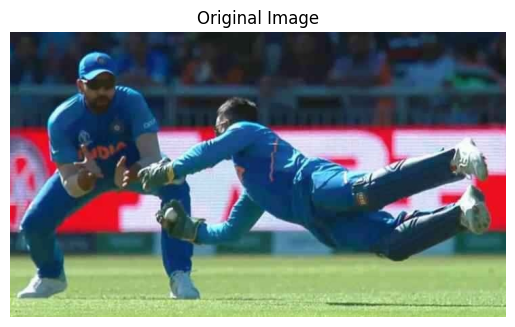

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

In [35]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Uploaded image:", filename)
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()
# Convert image into grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Load Haar Cascade face detection model
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Check model loading
if face_cascade.empty():
    raise ValueError("Face detection model not loaded.")

print("Face detection model loaded successfully!")
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))
for (x, y, w, h) in faces:

    cv2.rectangle(
        img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        img,
        "Face",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

# Display detected faces
result = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Face Detection Result")
plt.axis("off")
plt.show()
cv2.imwrite("face_detection_result.jpg", img)

print("Face detection completed successfully!")

files.download("face_detection_result.jpg")
